# T0121-R1：MDA 目标不变的战斗数值重估

## tl;dr

- 固定体验函数：W1 教学、W2 首个压力峰、W3 构筑回报、W4 策略峰、W5 成熟收官。
- 旧证据失效的主因不是“第一波少加了几个敌人”，而是采样早于当前实体弹体、ActorMotion/新寻路与普通受伤打断；同时只算原始 DPS，没有测接战、命中、目标分配、离散击杀和跨波战损。
- `BASELINE` 筛选中，第一波普通执行的单箭塔清场率为 97.5%；已实施方案保留现有受击动作与硬直，只把 W1 剑盾兵 HP `32 → 33`，跨过箭塔两发击杀断点，同一负向对照降到接近 0，而“艾达 + 布鲁诺 + 箭塔”的第一波仍稳定通过。
- 第二至第五波数值本轮不动；当前机制筛选仍把 W4 晚集结放在高风险区、W5 成熟准备放在既定 70–85% 可行区。这里的模型率只用于机制筛选，不等于真实玩家胜率。


## Context & Methods

决策：在不改 Dynamics/Aesthetics 目标的前提下，比较变更前 BASELINE 与用户确认后落地的 IMPLEMENTED Mechanics。

### Key Assumptions

- 权威输入来自 `data/enemy_waves.json`、`data/weapon_defs.json`、`data/armor_defs.json`、`data/defense_device_defs.json`、`data/npc_profiles.json` 与 `CombatSystem.gd` 的防御曲线。
- 筛选器用 0.1 秒离散时间镜像抬手、恢复、受伤打断、离散命中、过量伤害、接战时点、目标分配和器械承伤；它不替代 Godot 的物理碰撞、导航和实际玩家操作。
- `prepared / ordinary / late` 是执行质量敏感性带，不是玩家分布。真实首次/学会后胜率仍需 Main.tscn 多种子回放与盲测。
- 用户明确要求保留受击动作与硬直；BASELINE 与 IMPLEMENTED 都维持普通伤害取消 `windup / recovery` 的现状，并把打断次数作为独立指标。
- 已实施方案只把第一波 `raider_sword` 的 HP / Max HP 从 32 调为 33；器械、后四波敌军和战斗程序不变。


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

project_root = Path.cwd()
if not (project_root / "project.godot").exists():
    project_root = Path.cwd().parent
sys.path.insert(0, str(project_root / "analysis"))
import t0121_r1_balance_reestimation as model

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5.5), "axes.titlesize": 13, "axes.labelsize": 11})
ITERATIONS = 200


## Data

### 1. Load current authority inputs and audit discrete breakpoints

In [2]:
breakpoints = model.breakpoint_table()
input_curve = model.input_curve_table()

arrow_breakpoints = breakpoints[breakpoints["device"] == "wall_arrow_tower"].copy()
arrow_pivot = arrow_breakpoints.pivot_table(
    index=["wave", "enemy_type"],
    columns="contract",
    values="shots_to_kill",
    aggfunc="first",
).reset_index()
hp_pivot = arrow_breakpoints.pivot_table(index=["wave", "enemy_type"], columns="contract", values="enemy_hp", aggfunc="first").reset_index()
arrow_pivot = arrow_pivot.merge(hp_pivot, on=["wave", "enemy_type"], suffixes=("_shots", "_hp"))
arrow_pivot


contract,wave,enemy_type,BASELINE_shots,IMPLEMENTED_shots,BASELINE_hp,IMPLEMENTED_hp
0,1,raider_sword,2,3,32,33
1,2,raider_polearm,2,2,30,30
2,2,raider_sword,3,3,34,34
3,3,raider_archer,2,2,24,24
4,3,raider_sword,3,3,36,36
5,4,raider_cavalry,3,3,42,42
6,4,raider_crossbow,2,2,26,26
7,4,raider_polearm,3,3,34,34
8,4,raider_sword,3,3,34,34
9,5,raider_crossbow,2,2,28,28


### 2. Run the deterministic sensitivity matrix

In [3]:
samples = model.run_matrix(ITERATIONS)
summary = model.summarize_matrix(samples)
summary.head(12)


,wave,contract,execution,tower_only,ada_only,model_clear_rate,duration_p10,duration_p50,duration_p90,npc_missing_hp_p50,npc_unconscious_p50,device_missing_hp_p50,devices_destroyed_p50,device_damage_share_p50,enemy_interrupts_p50,npc_interrupts_p50,enemy_device_target_share_p50
0,1,BASELINE,late,False,False,1.000,14.40,15.80,17.30,39.0,0.0,30.0,0.0,0.605469,5.0,3.0,0.067001
1,1,BASELINE,late,False,True,0.000,41.40,48.80,65.60,120.0,1.0,0.0,0.0,0.000000,4.0,18.5,0.000000
2,1,BASELINE,late,True,False,0.835,21.40,24.20,89.73,0.0,0.0,90.0,0.0,1.000000,5.0,0.0,0.150490
3,1,BASELINE,ordinary,False,False,1.000,11.60,13.00,14.40,22.0,0.0,18.0,0.0,0.523438,4.0,4.0,0.050770
4,1,BASELINE,ordinary,False,True,0.500,23.39,36.35,113.92,118.5,0.5,0.0,0.0,0.000000,7.0,29.0,0.000000
5,1,BASELINE,ordinary,True,False,0.975,21.40,22.80,25.60,0.0,0.0,75.0,0.0,1.000000,4.0,0.0,0.136874
6,1,BASELINE,prepared,False,False,1.000,10.20,11.35,12.30,15.0,0.0,12.0,0.0,0.460938,3.0,4.0,0.039421
7,1,BASELINE,prepared,False,True,0.845,21.28,25.30,70.81,99.0,0.0,0.0,0.0,0.000000,6.0,28.5,0.000000
8,1,BASELINE,prepared,True,False,0.995,21.40,22.80,24.34,0.0,0.0,69.0,0.0,1.000000,4.0,0.0,0.132003
9,1,IMPLEMENTED,late,False,False,1.000,15.80,17.35,19.41,52.0,0.0,39.0,0.0,0.594697,8.0,5.0,0.070559


## Results

### 3. Compare the negative control and the planned build

In [4]:
focus = summary[
    ((summary["wave"] == 1) & (summary["execution"] == "ordinary"))
    | ((summary["wave"] == 4) & (summary["execution"] == "late") & ~summary["tower_only"] & ~summary["ada_only"])
    | ((summary["wave"] == 5) & (summary["execution"] == "prepared") & ~summary["tower_only"] & ~summary["ada_only"])
][[
    "wave", "contract", "execution", "tower_only", "ada_only", "model_clear_rate",
    "duration_p10", "duration_p50", "duration_p90", "npc_missing_hp_p50",
    "device_missing_hp_p50", "device_damage_share_p50", "enemy_interrupts_p50",
    "npc_interrupts_p50",
]]
focus


,wave,contract,execution,tower_only,ada_only,model_clear_rate,duration_p10,duration_p50,duration_p90,npc_missing_hp_p50,device_missing_hp_p50,device_damage_share_p50,enemy_interrupts_p50,npc_interrupts_p50
3,1,BASELINE,ordinary,False,False,1.000,11.60,13.00,14.40,22.0,18.0,0.523438,4.0,4.0
4,1,BASELINE,ordinary,False,True,0.500,23.39,36.35,113.92,118.5,0.0,0.000000,7.0,29.0
5,1,BASELINE,ordinary,True,False,0.975,21.40,22.80,25.60,0.0,75.0,1.000000,4.0,0.0
12,1,IMPLEMENTED,ordinary,False,False,1.000,12.70,14.05,15.81,29.5,21.0,0.511364,6.0,6.0
13,1,IMPLEMENTED,ordinary,False,True,0.495,23.48,42.65,113.91,120.0,0.0,0.000000,7.0,29.0
14,1,IMPLEMENTED,ordinary,True,False,0.000,49.18,60.60,85.08,0.0,110.0,1.000000,7.0,0.0
30,4,BASELINE,late,False,False,0.375,30.08,35.80,50.36,659.0,275.0,0.361608,31.0,89.5
33,4,IMPLEMENTED,late,False,False,0.375,30.08,35.80,50.36,659.0,275.0,0.361608,31.0,89.5
38,5,BASELINE,prepared,False,False,0.785,25.58,30.35,41.83,636.5,385.0,0.338621,50.0,109.5
41,5,IMPLEMENTED,prepared,False,False,0.785,25.58,30.35,41.83,636.5,385.0,0.338621,50.0,109.5


In [5]:
checks = {
    "baseline_w1_tower_only_exposes_problem": float(focus.query("wave == 1 and contract == 'BASELINE' and tower_only")["model_clear_rate"].iloc[0]) >= 0.80,
    "implemented_w1_tower_only_is_negative_control": float(focus.query("wave == 1 and contract == 'IMPLEMENTED' and tower_only")["model_clear_rate"].iloc[0]) <= 0.20,
    "implemented_w1_planned_build_remains_stable": float(focus.query("wave == 1 and contract == 'IMPLEMENTED' and not tower_only and not ada_only")["model_clear_rate"].iloc[0]) >= 0.95,
    "implemented_w4_late_execution_stays_peak_like": 0.25 <= float(focus.query("wave == 4 and contract == 'IMPLEMENTED'")["model_clear_rate"].iloc[0]) <= 0.60,
    "implemented_w5_prepared_is_inside_screening_guardrail": 0.65 <= float(focus.query("wave == 5 and contract == 'IMPLEMENTED'")["model_clear_rate"].iloc[0]) <= 0.90,
}
assert all(checks.values()), checks
checks


{'baseline_w1_tower_only_exposes_problem': True,
 'implemented_w1_tower_only_is_negative_control': True,
 'implemented_w1_planned_build_remains_stable': True,
 'implemented_w4_late_execution_stays_peak_like': True,
 'implemented_w5_prepared_is_inside_screening_guardrail': True}

### 4. Visualize where the arrow-tower breakpoint changes

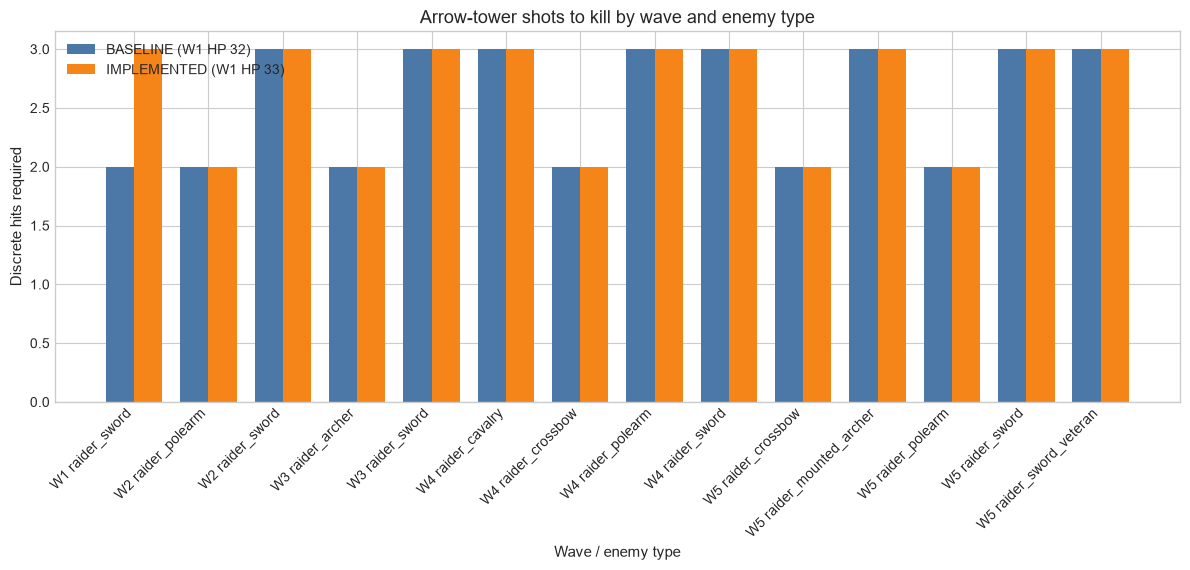

In [6]:
plot_rows = arrow_pivot.copy()
plot_rows["label"] = plot_rows.apply(lambda row: f"W{int(row.wave)} {row.enemy_type}", axis=1)
x = np.arange(len(plot_rows))
width = 0.38
fig, ax = plt.subplots(figsize=(12, 5.8))
ax.bar(x - width / 2, plot_rows["BASELINE_shots"], width, label="BASELINE (W1 HP 32)", color="#4C78A8")
ax.bar(x + width / 2, plot_rows["IMPLEMENTED_shots"], width, label="IMPLEMENTED (W1 HP 33)", color="#F58518")
ax.set_title("Arrow-tower shots to kill by wave and enemy type")
ax.set_ylabel("Discrete hits required")
ax.set_xlabel("Wave / enemy type")
ax.set_xticks(x, plot_rows["label"], rotation=45, ha="right")
ax.legend()
fig.tight_layout()
plt.show()


### 5. Compare the five-wave mechanical curve

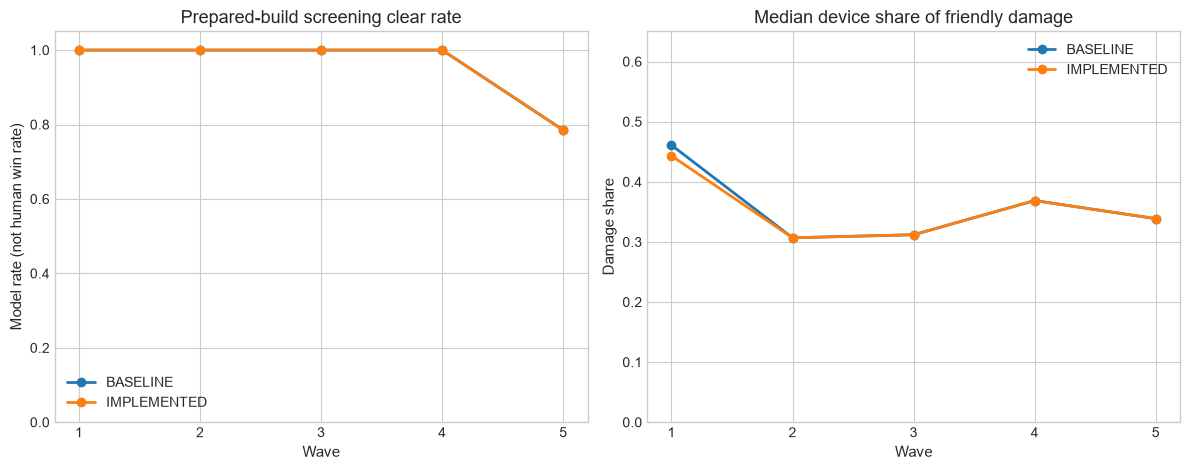

In [7]:
curve_rows = summary[(summary["execution"] == "prepared") & (~summary["tower_only"]) & (~summary["ada_only"])].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for contract, group in curve_rows.groupby("contract"):
    group = group.sort_values("wave")
    axes[0].plot(group["wave"], group["model_clear_rate"], marker="o", linewidth=2, label=contract)
    axes[1].plot(group["wave"], group["device_damage_share_p50"], marker="o", linewidth=2, label=contract)
axes[0].set(title="Prepared-build screening clear rate", xlabel="Wave", ylabel="Model rate (not human win rate)", xticks=range(1, 6), ylim=(0, 1.05))
axes[1].set(title="Median device share of friendly damage", xlabel="Wave", ylabel="Damage share", xticks=range(1, 6), ylim=(0, 0.65))
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()


## Takeaways

1. 旧的连续 DPS 表没有错误到“算术算错”，而是层级用错：它只能审计输入，不能推出体验。当前第一波恰好处在 `32 HP = 2 × 16` 的离散断点；把 W1 HP 调为 33 后需要 3 发，暴露时间显著增加。
2. 普通受伤打断同时取消抬手和恢复，会让伤害额外携带硬直收益，也可能因取消恢复而改变下一轮起手。按用户要求，该动作与硬直不改；新方法必须把它作为既定机制逐次仿真并单独报告，不能用静态 DPS 代替。
3. 已实施方案只改变 W1 敌人 HP，保留 W1 计划构筑高容错、W3 器械反馈和 W5 成熟构筑可行性，同时使“只造塔、不集结任何人”成为明确负向对照。
4. 下一道门必须是可运行的 Main.tscn 物理矩阵：记录 P10/P50/P90、接战时间、实体命中、攻击打断、来源伤害占比、目标驻留、NPC/器械/建筑战损，并用连续五波快照检验恢复滚动。当前工作树的 Main headless 启动存在与本任务无关的场景/VFX 崩溃，所以本轮不能把筛选结果升级为 `VERIFIED`。
